# Homework 2 - Classification

## 1. Import libraries and load dataset

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

df = pd.read_csv(r"C:\Users\benes\OneDrive\Desktop\School\machine learning\homework 2\heart.csv")
print(df.head(10))

print(df.shape)

   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   52    1   0       125   212    0        1      168      0      1.0      2   
1   53    1   0       140   203    1        0      155      1      3.1      0   
2   70    1   0       145   174    0        1      125      1      2.6      0   
3   61    1   0       148   203    0        1      161      0      0.0      2   
4   62    0   0       138   294    1        1      106      0      1.9      1   
5   58    0   0       100   248    0        0      122      0      1.0      1   
6   58    1   0       114   318    0        2      140      0      4.4      0   
7   55    1   0       160   289    0        0      145      1      0.8      1   
8   46    1   0       120   249    0        0      144      0      0.8      2   
9   54    1   0       122   286    0        0      116      1      3.2      1   

   ca  thal  target  
0   2     3       0  
1   0     3       0  
2   0     3       0  
3   1     3       0 

## Check for missing values

In [37]:
print(df.isnull().sum())

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


# Inspect target

target
1    526
0    499
Name: count, dtype: int64


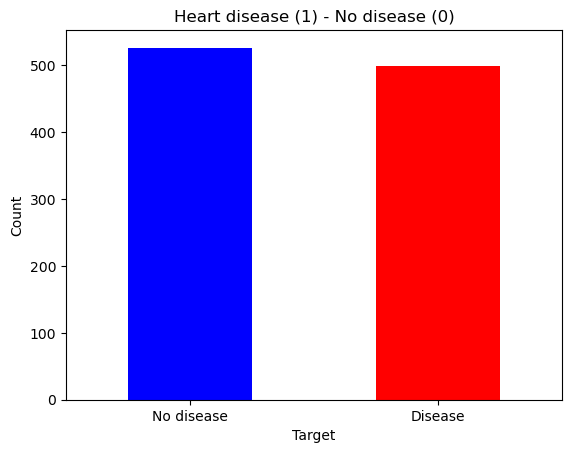

In [38]:
print(df['target'].value_counts())
df['target'].value_counts().plot(kind='bar', color=['blue', 'red'])
plt.title('Heart disease (1) - No disease (0)')
plt.xlabel('Target')
plt.ylabel('Count')
plt.xticks([0, 1], ['No disease', 'Disease'], rotation=0)
plt.show()

## Prepare and standardize data

In [39]:
X = df.drop('target', axis=1)
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

print("Training test size:", X_train.shape)
print("Test set size:", X_test.shape)

standard = StandardScaler()
X_train_standard = standard.fit_transform(X_train)
X_test_standard = standard.transform(X_test)

Training test size: (820, 13)
Test set size: (205, 13)


## Train model

In [40]:
model = LogisticRegression()
model.fit(X_train_standard, y_train)
print("Model trained")

Model trained


## Make predictions

In [43]:
y_pred = model.predict(X_test_standard)

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy*100, "%")

Accuracy: 80.97560975609757 %


## Confusion matrix

Confusion matrix:
 [[80 29]
 [10 86]]


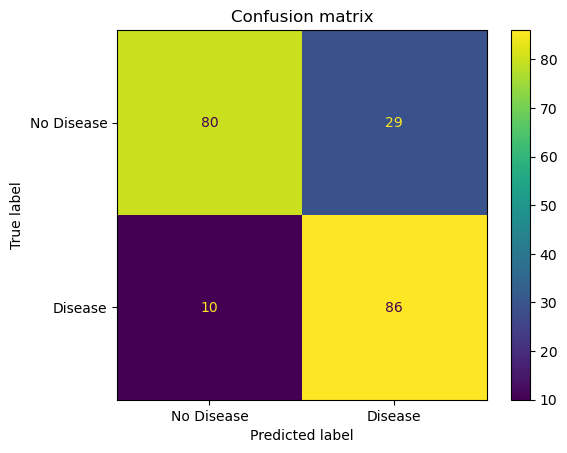

In [44]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix:\n", cm)

cm_disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Disease', 'Disease'])
cm_disp.plot()
plt.title('Confusion matrix')
plt.show()

## Same model with MinMaxScaler

In [45]:
minmax = MinMaxScaler()
X_train_minmax = minmax.fit_transform(X_train)
X_test_minmax = minmax.transform(X_test)

model_minmax = LogisticRegression(max_iter=1000)
model_minmax.fit(X_train_minmax, y_train)

y_pred_minmax = model_minmax.predict(X_test_minmax)
accuracy_minmax = accuracy_score(y_test, y_pred_minmax)
print("Accuracy:", accuracy_minmax*100, "%")

Accuracy: 80.0 %
